In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Set style
sns.set_theme(style="whitegrid")

In [17]:
# Load Data
data_path = os.path.join('data_csv', 'visuals_data_2000_2007.csv')
df = pd.read_csv(data_path, index_col=0, parse_dates=True)

# Display first few rows to verify data
print("Data Head:")
display(df.head())
print("\nColumns:")
print(df.columns)

Data Head:


,National_permits,National_population,National_housing starts,National_recessions,SF_permits,SF_population,CE_permits,CE_population,CR_permits,CR_population,LV_permits,LV_population
1959-01-01,NaN,NaN,1657.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1959-02-01,NaN,NaN,1667.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1959-03-01,NaN,NaN,1620.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1959-04-01,NaN,NaN,1590.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1959-05-01,NaN,NaN,1498.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Columns:
Index(['National_permits', 'National_population', 'National_housing starts',
       'National_recessions', 'SF_permits', 'SF_population', 'CE_permits',
       'CE_population', 'CR_permits', 'CR_population', 'LV_permits',
       'LV_population'],
      dtype='object')


In [18]:
print(df.index.min())
print(df.index.max())

1959-01-01 00:00:00
2025-08-01 00:00:00


## 1. National Population and Permits
Comparing National Population (Left Axis) and Building Permits (Right Axis).

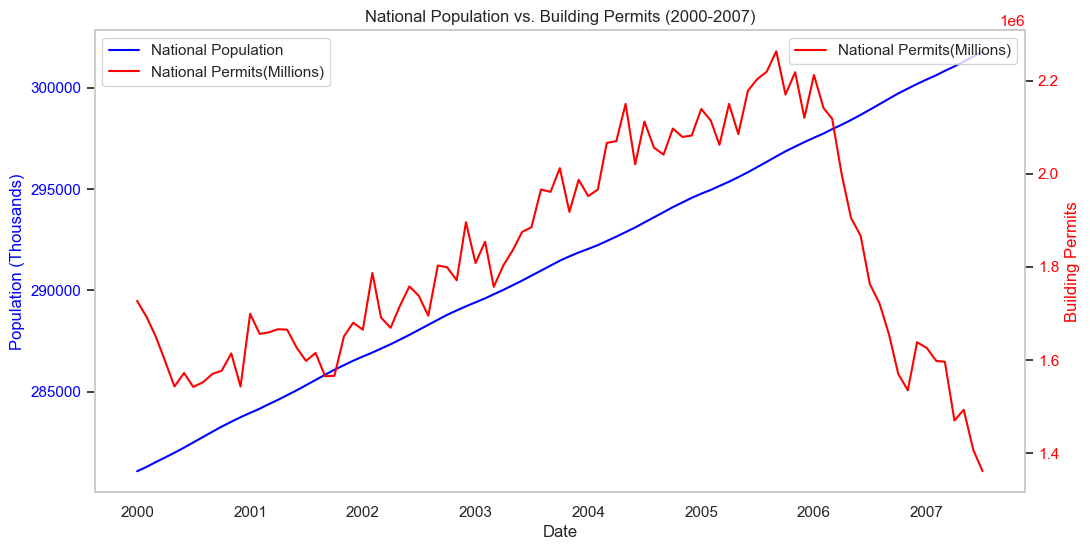

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Population on Left Axis
sns.lineplot(data=df, x=df.index, y='National_population', ax=ax1, color='blue', label='National Population')
ax1.set_ylabel('Population (Thousands)', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')
ax1.set_xlabel('Date')
ax1.grid(False) # Turn off grid for the first axis to avoid clutter

# Create Right Axis for Permits
ax2 = ax1.twinx()
sns.lineplot(data=df, x=df.index, y='National_permits', ax=ax2, color='red', label='National Permits(Millions)')
ax2.set_ylabel('Building Permits', color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.grid(False)

# Title and Layout
plt.title('National Population vs. Building Permits (2000-2007)')

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.show()

## 2. Metro Level Permits
Trends in building permits for all metropolitan areas.

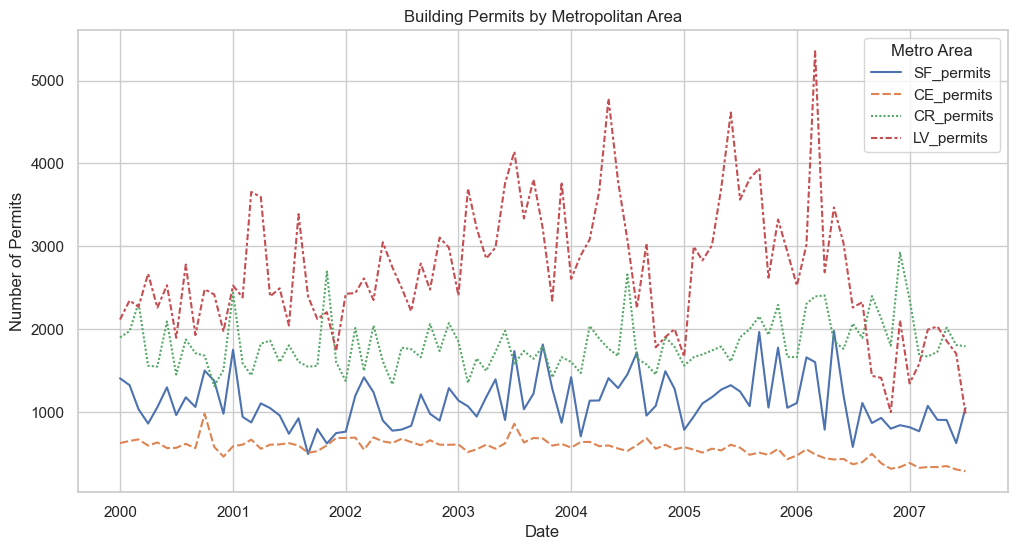

In [20]:
# Filter columns for Metro Permits (excluding National)
metro_permits_cols = [col for col in df.columns if 'permits' in col and 'National' not in col]

plt.figure(figsize=(12, 6))
sns.lineplot(data=df[metro_permits_cols])
plt.title('Building Permits by Metropolitan Area')
plt.ylabel('Number of Permits')
plt.xlabel('Date')
plt.legend(title='Metro Area')
plt.show()

## 3. Metro Level Populations
Trends in population for all metropolitan areas.

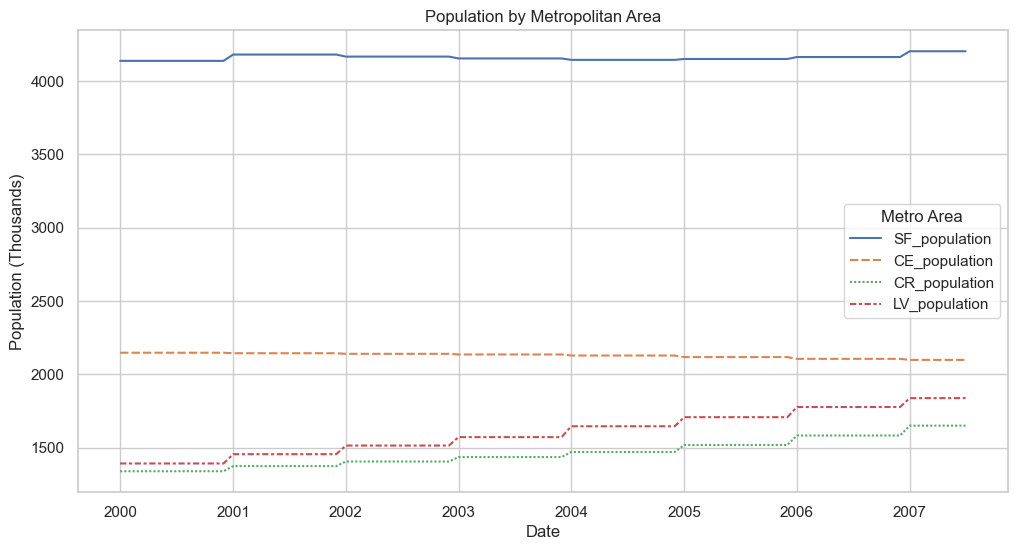

In [21]:
# Filter columns for Metro Population (excluding National)
metro_pop_cols = [col for col in df.columns if 'population' in col and 'National' not in col]

plt.figure(figsize=(12, 6))
sns.lineplot(data=df[metro_pop_cols])
plt.title('Population by Metropolitan Area')
plt.ylabel('Population (Thousands)')
plt.xlabel('Date')
plt.legend(title='Metro Area')
plt.show()

## 4. Permits per Capita
Calculating and visualizing Building Permits divided by Population for both National and Metro levels.
This metric helps normalize the permit data relative to the size of the population.

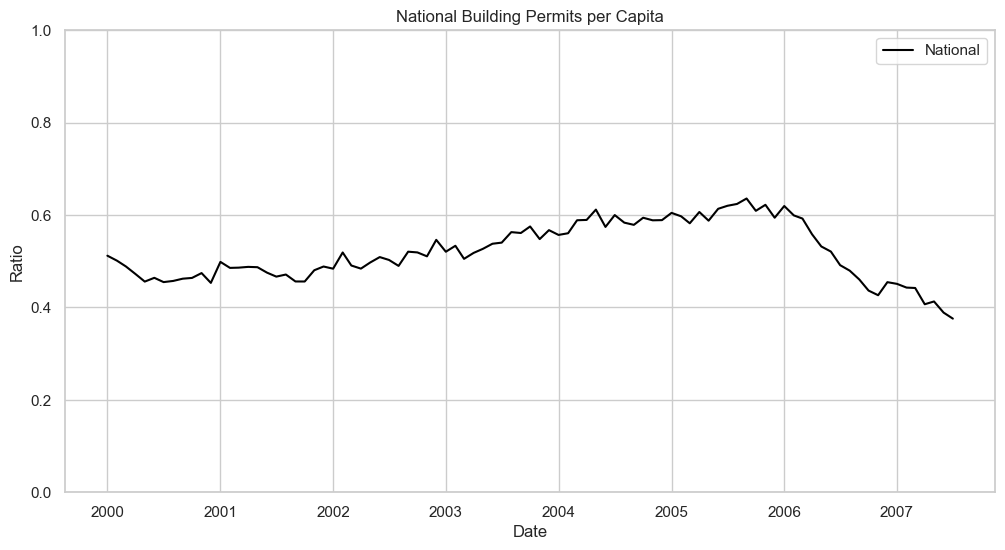

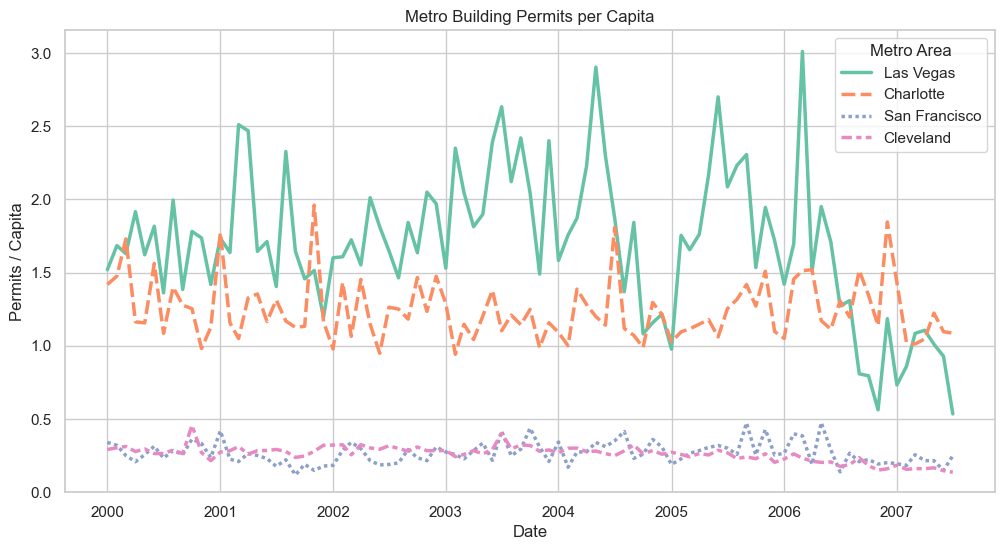

In [39]:
# Calculate Permits per Capita
df_per_capita = pd.DataFrame(index=df.index)

# National
if 'National_permits' in df.columns and 'National_population' in df.columns:
    df_per_capita['National'] = df['National_permits'] / df['National_population'] /12

# Metros
# Extract city prefixes from columns
cities = set([col.split('_')[0] for col in df.columns if '_' in col and 'National' not in col])

for city in cities:
    permits_col = f'{city}_permits'
    pop_col = f'{city}_population'
    if permits_col in df.columns and pop_col in df.columns:
        df_per_capita[city] = df[permits_col] / df[pop_col]

# Plot National
plt.figure(figsize=(12, 6))
if 'National' in df_per_capita.columns:
    sns.lineplot(data=df_per_capita[['National']], palette=['black'])
    plt.title('National Building Permits per Capita')
    plt.ylabel('Ratio')
    plt.xlabel('Date')
    plt.ylim(bottom=0)
    plt.ylim(top=1.0)
    plt.show()

# Plot Metros
metro_cols = [col for col in df_per_capita.columns if col != 'National']
if metro_cols:
    # Rename and Sort
    city_map = {
        'SF': 'San Francisco',
        'CE': 'Cleveland',
        'CR': 'Charlotte',
        'LV': 'Las Vegas'
    }
    # Rename columns, keeping original if not in map
    df_metro_plot = df_per_capita[metro_cols].rename(columns=lambda x: city_map.get(x, x))
    
    # Sort by peak value (descending)
    peak_values = df_metro_plot.max()
    sorted_cols = peak_values.sort_values(ascending=False).index.tolist()
    df_metro_plot = df_metro_plot[sorted_cols]

    custom_colors = ['#003f5c', '#ffa600', '#4c8a9f', '#9a2e3f']

    plt.figure(figsize=(12, 6))
    sns.lineplot(data=df_metro_plot, palette='Set2', linewidth=2.5)
    plt.title('Metro Building Permits per Capita')
    plt.ylabel('Permits / Capita')
    plt.xlabel('Date')
    plt.ylim(bottom=0)
    plt.legend(title='Metro Area')
    plt.show()

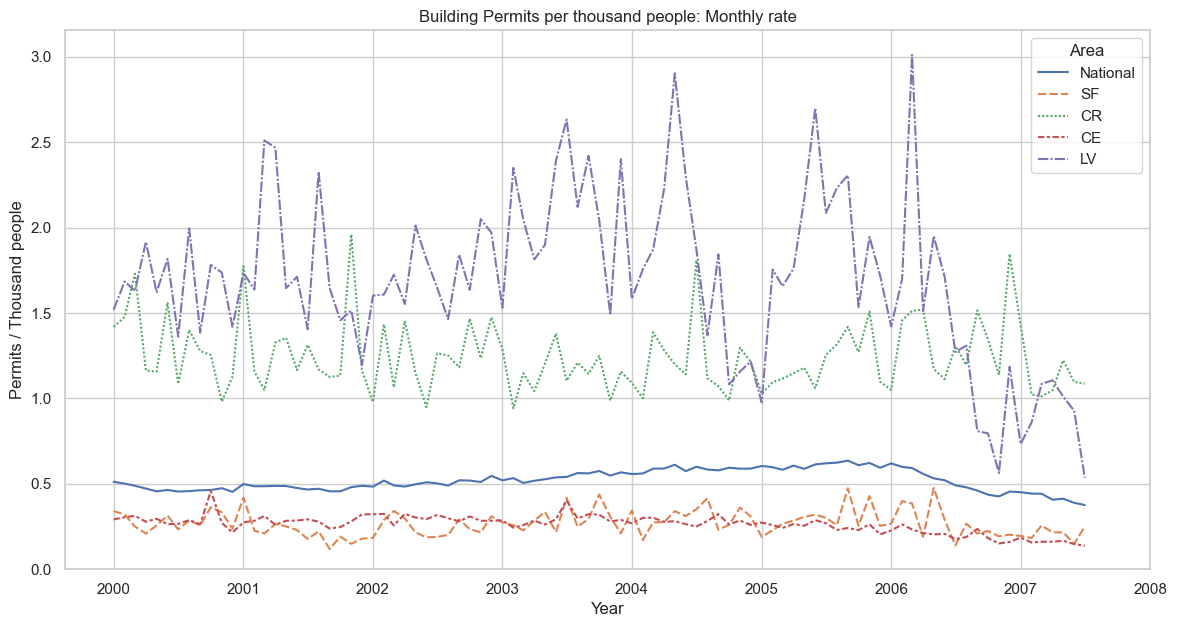

In [28]:
# --- Combined Plot: National and Metro Permits per Capita ---
# Recalculating to ensure National is adjusted for monthly rate (divided by 12)

df_per_capita_combined = pd.DataFrame(index=df.index)

# National Calculation
# National Permits are usually reported as Seasonally Adjusted Annual Rate (SAAR).
# We divide by 12 to get the approximate monthly volume, making it comparable to Metro data.
if 'National_permits' in df.columns and 'National_population' in df.columns:
    df_per_capita_combined['National'] = (df['National_permits'] / df['National_population']) / 12

# Metro Calculation
# Metro Permits are typically reported as monthly totals.
cities = set([col.split('_')[0] for col in df.columns if '_' in col and 'National' not in col])

for city in cities:
    permits_col = f'{city}_permits'
    pop_col = f'{city}_population'
    if permits_col in df.columns and pop_col in df.columns:
        df_per_capita_combined[city] = df[permits_col] / df[pop_col]

# Plotting all on one graph
plt.figure(figsize=(14, 7))
sns.lineplot(data=df_per_capita_combined)
plt.title('Building Permits per thousand people: Monthly rate')
plt.ylabel('Permits / Thousand people')
plt.xlabel('Year')
plt.xlim(right=pd.Timestamp('2008-01-01'))
plt.ylim(bottom=0)
plt.legend(title='Area')
plt.show()

## 5. Case-Shiller House Price Indices
Visualizing the trends in Case-Shiller Home Price Indices for National, 10-City Composite, and specific Metro areas.

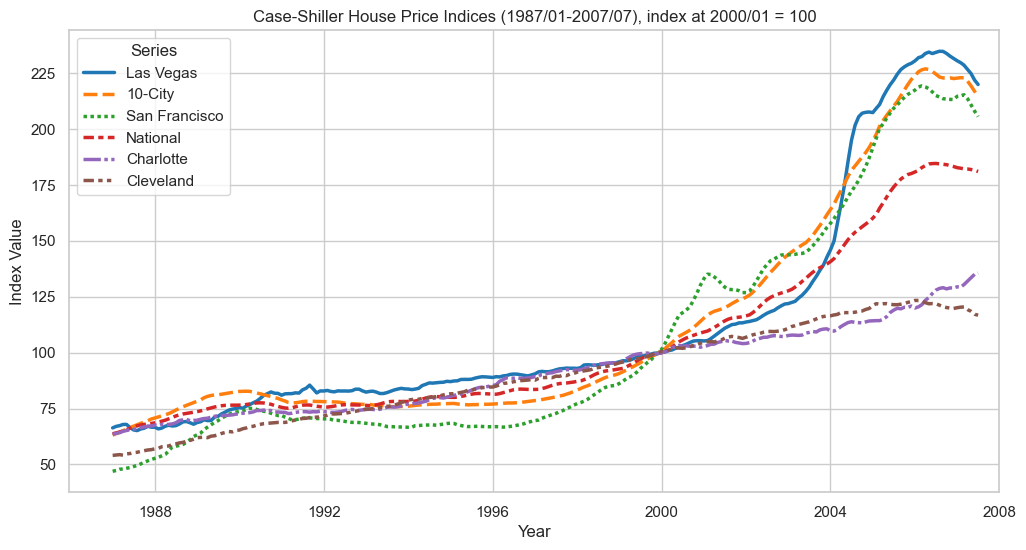

In [24]:
# Load House Price Data
hpi_path = os.path.join('data_csv', 'var_data_1987_2007.csv')
df_hpi = pd.read_csv(hpi_path, index_col=0, parse_dates=True)

# Use full dataset (starts from 1987)
df_hpi_all = df_hpi

# Select HPI columns and define labels
hpi_cols = ['cs-national', 'cs-10-city', 'SF_hpi', 'CE_hpi', 'CR_hpi', 'LV_hpi']
labels_map = {
    'cs-national': 'National',
    'cs-10-city': '10-City',
    'SF_hpi': 'San Francisco',
    'CE_hpi': 'Cleveland',
    'CR_hpi': 'Charlotte',
    'LV_hpi': 'Las Vegas'
}

# Sort columns by the last value (descending) to order legend by magnitude
last_values = df_hpi_all[hpi_cols].iloc[-1]
sorted_cols = last_values.sort_values(ascending=False).index.tolist()

# Create sorted dataframe with proper labels
df_plot = df_hpi_all[sorted_cols].rename(columns=labels_map)

# Plot
plt.figure(figsize=(12, 6))
# Use 'tab10' palette for better distinction and increase line width
sns.lineplot(data=df_plot, palette='tab10', linewidth=2.5)
plt.title('Case-Shiller House Price Indices (1987/01-2007/07), index at 2000/01 = 100')
plt.ylabel('Index Value')
plt.xlabel('Year')
plt.xlim(right=pd.Timestamp('2008-01-01'))
plt.legend(title='Series')
plt.show()

## 6. Economic Indicators
Visualizing Federal Funds Rate, Industrial Production, and CPI from 1987.

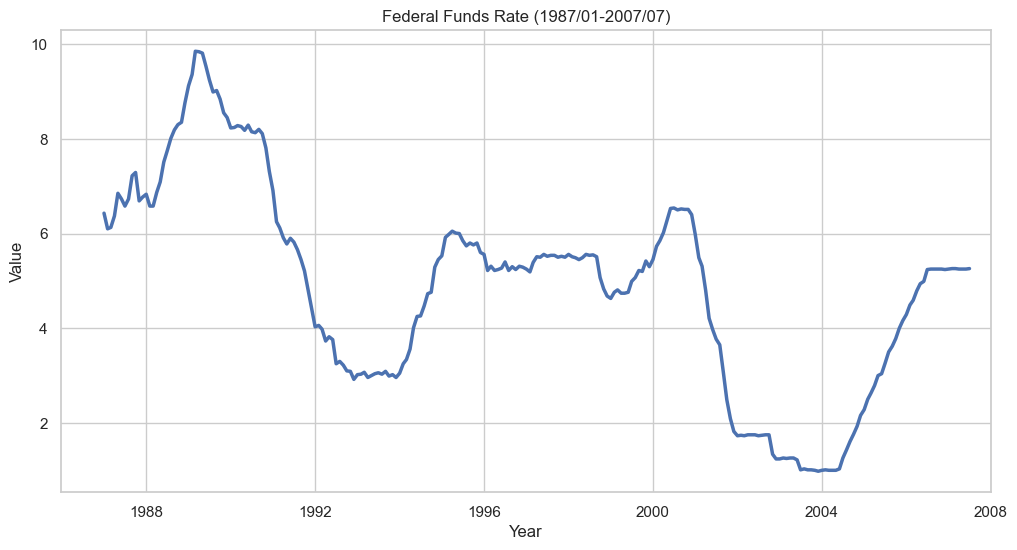

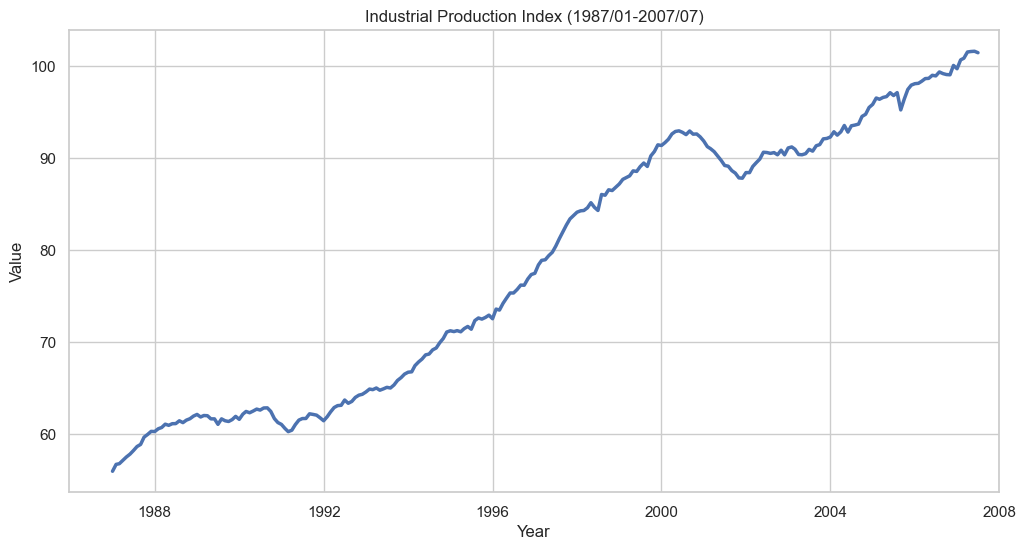

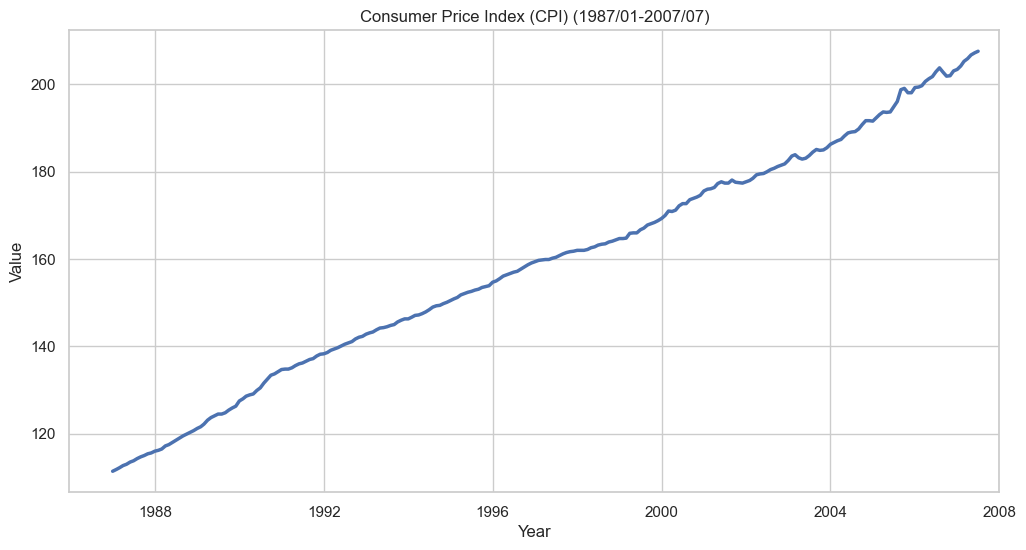

In [25]:
# Define columns for economic indicators
econ_cols = {
    'fedfunds': 'Federal Funds Rate',
    'indpro': 'Industrial Production Index',
    'cpi': 'Consumer Price Index (CPI)'
}

# Plot each indicator
for col, title in econ_cols.items():
    plt.figure(figsize=(12, 6))
    sns.lineplot(data=df_hpi, x=df_hpi.index, y=col, linewidth=2.5)
    plt.title(f'{title} (1987/01-2007/07)')
    plt.ylabel('Value')
    plt.xlabel('Year')
    plt.xlim(right=pd.Timestamp('2008-01-01'))
    plt.show()

## 7. Housing Starts and Recessions
Visualizing Housing Starts from 1959 with recession shading.

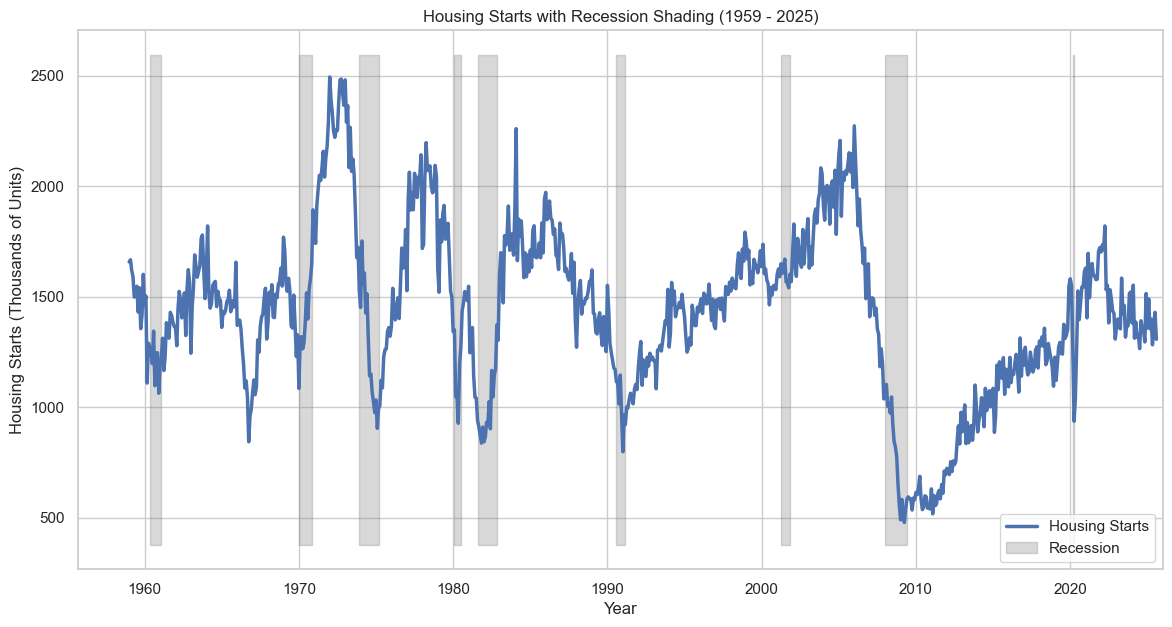

In [26]:
# Load Data
data_path = os.path.join('data_csv', 'visuals_data_2000_2007.csv')
df_long = pd.read_csv(data_path, index_col=0, parse_dates=True)

# Plot
plt.figure(figsize=(14, 7))
sns.lineplot(data=df_long, x=df_long.index, y='National_housing starts', linewidth=2.5, label='Housing Starts')

# Shade recessions
# Get current y-axis limits to shade the full height
y_min, y_max = plt.ylim()
plt.fill_between(df_long.index, y_min, y_max, where=df_long['National_recessions'] == 1, 
                 color='grey', alpha=0.3, label='Recession')

plt.title('Housing Starts with Recession Shading (1959 - 2025)')
plt.ylabel('Housing Starts (Thousands of Units)')
plt.xlabel('Year')
plt.xlim(right=pd.Timestamp('2026-01-01'))
plt.legend()
plt.show()